In [ ]:
org_class = 'normal'
target_class = 'highgrade_dysplasia'
import pickle
import yaml
yaml_paths = './data/data_dir.yaml'
with open(yaml_paths, 'r') as yaml_file:
    file_paths = yaml.safe_load(yaml_file)
    
save_dir = file_paths['HunCRC_data']['traversal_images_dir']

with open(save_dir,'rb') as f:
    traverse_data = pickle.load(f)
print(traverse_data.keys())

dict_keys(['img', 'idx', 'step_size', 'gland_masks', 'predicted_classes', 'goblet_cell_detection', 'AAE_Delta_map_resizemean_consecutive_full_grade_oldAAE', 'patient_across', 'delta_array', 'shuffle_dummy_idx', 'goblet_cell_detection_padded_to_640', 'goblet_cell_detection_paddedto540forepi_keepsizeforgoblet', 'goblet_cell_detection_paddedto640'])


In [ ]:
#generate delta-map between executive steps 

if 'Delta_map_AAE' not in traverse_data:
    import numpy as np
    import torch
    import torchvision.transforms as transforms
    import skimage.transform
    import torch.nn as nn
#%% load encoder model
    class Encoder(nn.Module):
        def __init__(self, nc, nf, nz):
            super(Encoder, self).__init__()
            self.net = nn.Sequential(
                nn.Conv2d(nc, nf, 5, 2, 2, bias=False),
                nn.BatchNorm2d(nf),
                nn.LeakyReLU(0.2, inplace=True),

                nn.Conv2d(nf, nf*2, 5, 2, 2, bias=False),
                nn.BatchNorm2d(nf*2),
                nn.LeakyReLU(0.2, inplace=True),

                nn.Conv2d(nf*2, nf*4, 5, 2, 2, bias=False),
                nn.BatchNorm2d(nf*4),
                nn.LeakyReLU(0.2, inplace=True),            
                
                nn.Conv2d(nf*4, nf*4, 5, 2, 2, bias=False),
                nn.BatchNorm2d(nf*4),
                nn.LeakyReLU(0.2, inplace=True),
                
                nn.Conv2d(nf*4, nf*4, 5, 2, 2, bias=False),
                nn.BatchNorm2d(nf*4),
                nn.LeakyReLU(0.2, inplace=True),

                nn.Flatten(),
                nn.Linear(in_features=7*7*nf*4, out_features=nz),
            )

        def forward(self, input):
            y =  self.net(input)
            return y
    #Pass images through encoder/cls filter
    nz=1024
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    # enc_Path = file_paths['WEIGHTS']['AAE']['Encoder']['n1024']
    enc_Path = f'./checkpoints/AAE_model_n{nz}_enc.pth'
    enc = Encoder(nc=3, nf=256, nz=nz)
    enc.load_state_dict(torch.load(enc_Path))
    enc = enc.to(device)
    enc.eval()
    sub_model = enc.net[:9]
    transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])
    
    observed_img =traverse_data['img']
    array_list = []
    for i in range(observed_img.shape[0]):
        batch = []
        for j in range(observed_img.shape[1]):
            batch.append(transform(observed_img[i,j]))
        batch = torch.stack(batch).to(device)
        array_list.append(sub_model(batch).cpu().detach().numpy())
    array_list = np.array(array_list)

    #Compute the delta array and rescale it to 224x224
    #Compute the delta array and rescale it to 224x224
    Delta_array_list = array_list[:,1:,:,:]-array_list[:,:-1,:,:]
    import skimage
    mean_rescale_delta_array_list = []
    for i in range(Delta_array_list.shape[0]):
        mean_rescale_delta_array_list_i = []
        for j in range(Delta_array_list.shape[1]):
            mean_delta_array_list_i_j = np.abs(Delta_array_list[i][j]).mean(axis = 0)
            rescale_delta_array_list_i_j = skimage.transform.resize(mean_delta_array_list_i_j, [224, 224], order = 2)
            mean_rescale_delta_array_list_i.append(rescale_delta_array_list_i_j)
        mean_rescale_delta_array_list_i = np.array(mean_rescale_delta_array_list_i)
        mean_rescale_delta_array_list.append(mean_rescale_delta_array_list_i)
    mean_rescale_delta_array_list = np.array(mean_rescale_delta_array_list)
    traverse_data['Delta_map_AAE'] = mean_rescale_delta_array_list
    save_dir = file_paths['HunCRC_data']['traversal_images_dir']
    with open(save_dir,'wb') as f:
        pickle.dump(traverse_data, f, protocol=4)
    

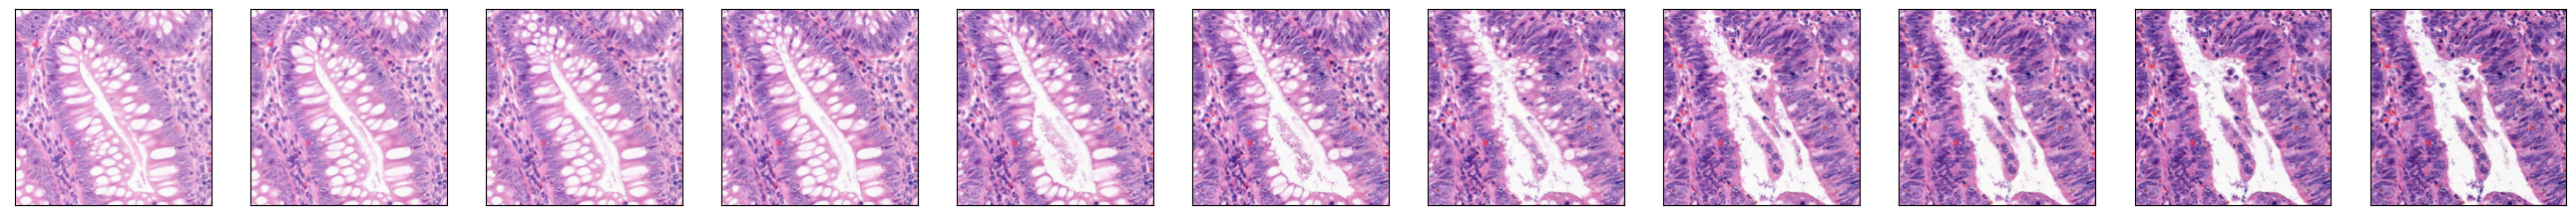

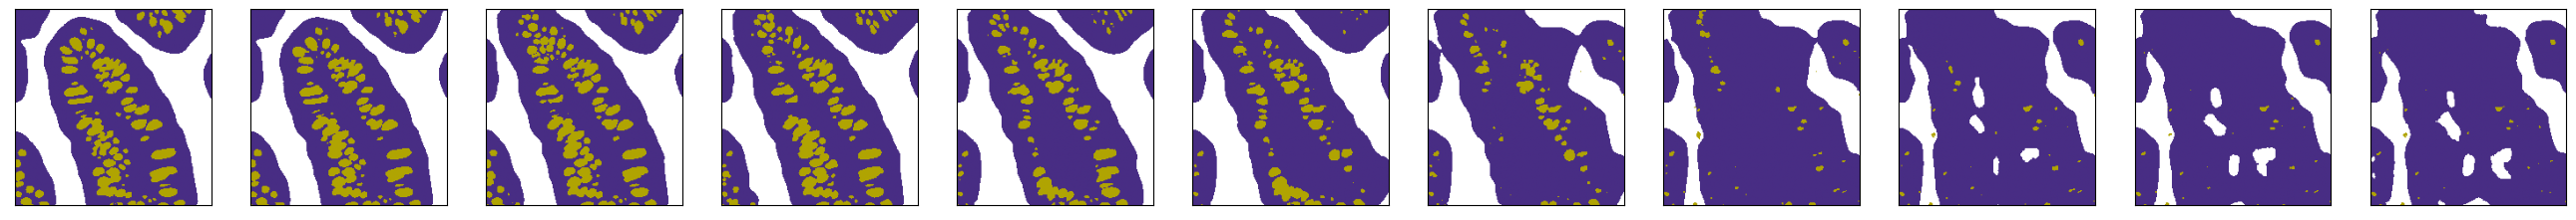

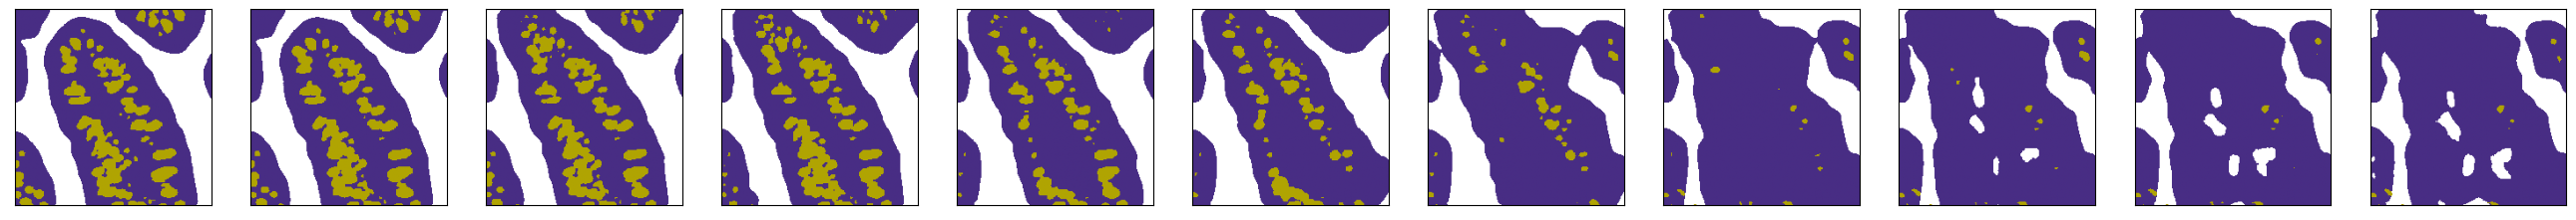

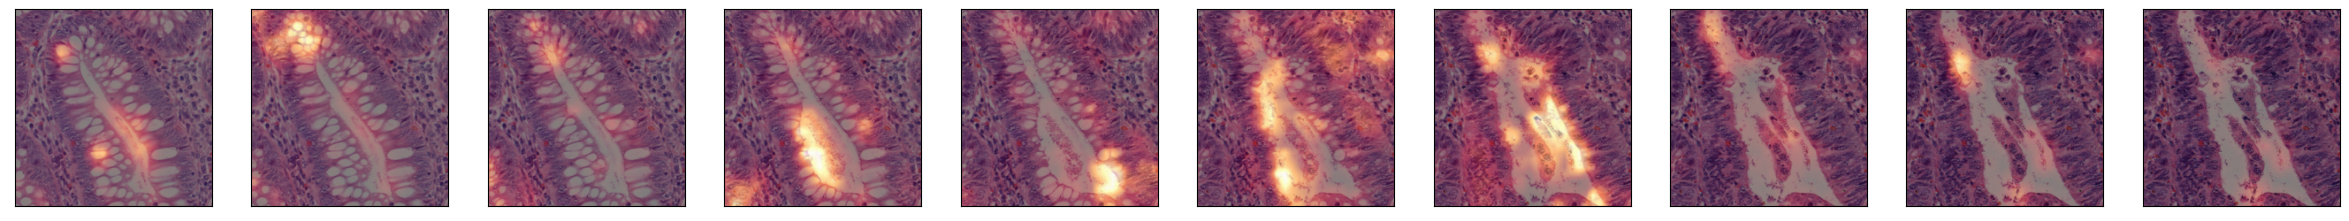

In [ ]:
# idx = np.random.choice(traverse_data['img'].shape[0])
idx =792# 431#590 #792 
from matplotlib import pyplot as plt
import numpy as np
import cv2

def plot_mask(gobblet_mask, gland_mask):
    goblet_Color=np.array([176,164,2])/255
    gland_corlor = np.array([72,45,132])/255
    bgColor=np.array([255,255,255])/255
    # immuneColor=np.array([239,87,255])/255
    # immuneColor=np.array([61,239,253])/255
    cmap=np.stack((bgColor,gland_corlor, goblet_Color))
    # cmap=np.stack((bgColor,vasColor, nonTumoColor, tumColor, immuneColor))
    
    mask=np.uint8(gland_mask.copy())
    mask[gobblet_mask==1]=2
    # mask[nuclei_mask==3]=4
    maskRGB=cmap[mask]
    return maskRGB

plt.figure(figsize=(33,3))
traverse_list = traverse_data['img']
num_traverse_step = traverse_data['img'].shape[1]
for i in range(num_traverse_step):
    plt.subplot(1, num_traverse_step, i+1)
    plt.imshow(traverse_list[idx,i])
    # plt.title(f'Step: {i} \n {class_dict[traverse_data["predicted_classes"]["classes"][idx,i]]}')
    plt.xticks([])
    plt.yticks([])
plt.show()

plt.figure(figsize=(33,3))
traverse_list = traverse_data['gland_masks'][idx]
num_traverse_step = traverse_data['gland_masks'][idx].shape[0]

goblet_mask_list = []
for i in range(num_traverse_step):
    goblet_mask_list.append(cv2.resize(traverse_data['goblet_cell_detection']['goblet_seg'][idx][i], (224, 224), interpolation=cv2.INTER_NEAREST))
goblet_mask_list = np.array(goblet_mask_list)
for i in range(num_traverse_step):
    plt.subplot(1, num_traverse_step, i+1)
    merge_mask = plot_mask(goblet_mask_list[i], traverse_list[i])
    plt.imshow(merge_mask)
    plt.xticks([])
    plt.yticks([])
    # plt.axis('off')
plt.figure(figsize=(33,3))

    # plt.axis('off')

traverse_list = traverse_data['img']
num_traverse_step = traverse_data['img'].shape[1]
delta_map_list = traverse_data['Delta_map_AAE'][idx]
normalize_delta_map = (delta_map_list - delta_map_list.min()) / (delta_map_list.max() - delta_map_list.min())
plt.figure(figsize=(3*10,3))
for i in range(num_traverse_step-1):
    plt.subplot(1, num_traverse_step-1, i+1)
    plt.imshow(traverse_list[idx,i+1])
    
    plt.imshow(normalize_delta_map[i], cmap='afmhot', alpha=0.5, vmin=0, vmax=1)
    # plt.title(f'Step: {i} \n {class_dict[traverse_data["predicted_classes"]["classes"][idx,i]]}')
    plt.xticks([])
    plt.yticks([])
plt.show()

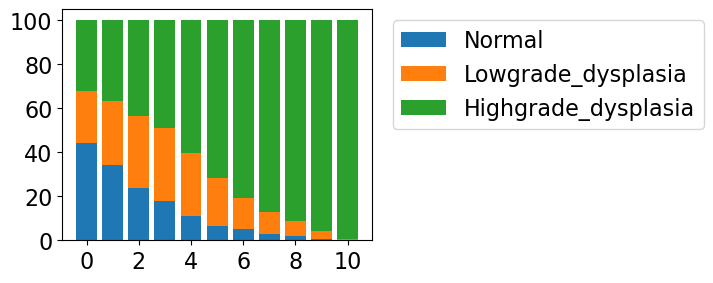

In [3]:
prediction_class_name = traverse_data['predicted_classes']['classes']

classes = np.unique(prediction_class_name)
traverse_steps = np.arange(prediction_class_name.shape[1])
class_distribution = []
for step in traverse_steps:
    class_counts = [np.sum(prediction_class_name[:, step] == cls) for cls in classes]
    class_distribution.append(class_counts)
class_distribution = np.array(class_distribution)
class_distribution = class_distribution / class_distribution.sum(axis=1, keepdims=True) * 100
#plot Stacked Percentage Bar Plot In MatPlotLib
class_dict = {0: 'Normal', 1: 'Lowgrade_dysplasia', 2: 'Highgrade_dysplasia', 3: 'adenocarcinoma'}
plt.figure(figsize=(4,3))
bottom = np.zeros(len(traverse_steps))
for i, cls in enumerate(classes):
    plt.bar(traverse_steps, class_distribution[:, i], bottom=bottom, label=class_dict[cls])
    bottom += class_distribution[:, i]
# plt.xlabel('Traverse Step')
# plt.ylabel('Percentage (%)')
# plt.title('Predicted Class Distribution Across Traverse Steps')
#set legend outside of the right top corner
plt.legend(bbox_to_anchor=(1.03, 1), loc='upper left', fontsize=16)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.show()

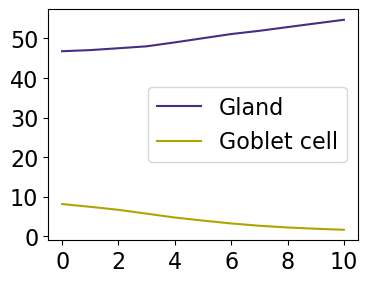

In [ ]:

goblet_Color=np.array([176,164,2])/255
gland_corlor = np.array([72,45,132])/255
plt.figure(figsize=(4,3))
plt.plot(np.sum(traverse_data['gland_masks'], axis=(2,3)).mean(axis=0)/(224*224)*100, label='Gland', color=gland_corlor)
goblet_size = traverse_data['goblet_cell_detection']['goblet_seg'].shape[2]*traverse_data['goblet_cell_detection']['goblet_seg'].shape[3]
plt.plot(np.sum(traverse_data['goblet_cell_detection']['goblet_seg'], axis=(2,3)).mean(axis=0)/goblet_size*100, label='Goblet cell', color=goblet_Color)
# plt.xlabel('Traverse step', fontsize=16)
# plt.ylabel('Percentage (%)', fontsize=16)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.legend(fontsize=16)


/project/bioinformatics/Rajaram_lab/shared/Environment/Conda/Thuongenv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1509: UndefinedMetricWarning: Jaccard is ill-defined and being set to 0.0 due to no true or predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/project/bioinformatics/Rajaram_lab/shared/Environment/Conda/Thuongenv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1509: UndefinedMetricWarning: Jaccard is ill-defined and being set to 0.0 due to no true or predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/project/bioinformatics/Rajaram_lab/shared/Environment/Conda/Thuongenv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1509: UndefinedMetricWarning: Jaccard is ill-defined and being set to 0.0 due to no true or predicted samples. Use `ze

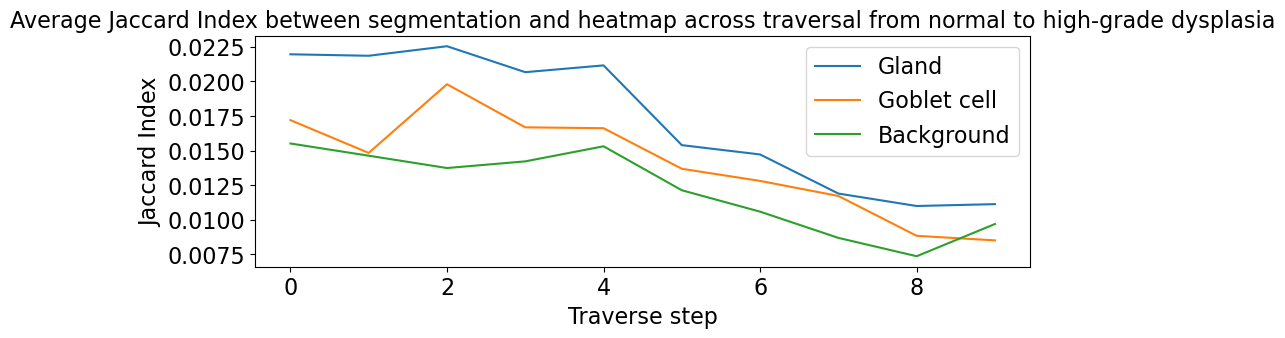

/project/bioinformatics/Rajaram_lab/shared/Environment/Conda/Thuongenv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1509: UndefinedMetricWarning: Jaccard is ill-defined and being set to 0.0 due to no true or predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/project/bioinformatics/Rajaram_lab/shared/Environment/Conda/Thuongenv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1509: UndefinedMetricWarning: Jaccard is ill-defined and being set to 0.0 due to no true or predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/project/bioinformatics/Rajaram_lab/shared/Environment/Conda/Thuongenv/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1509: UndefinedMetricWarning: Jaccard is ill-defined and being set to 0.0 due to no true or predicted samples. Use `ze

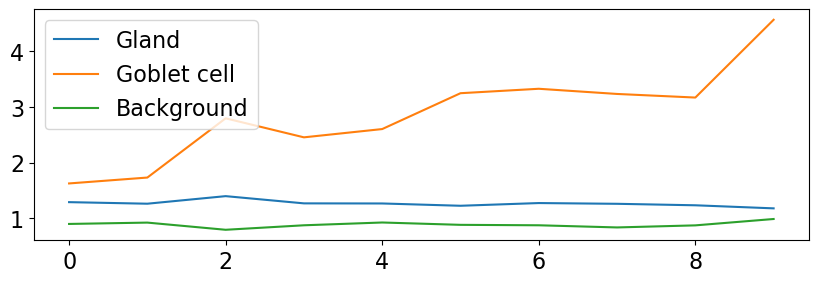

{'Gland': 1.2679964381911832, 'Goblet cell': 2.874358634037958, 'Background': 0.8898728981548663}


In [ ]:
#show jaccard rate between gland mask and heatmap (binarized at 0.5) across traverse step
from sklearn.metrics import jaccard_score
traverse_list = traverse_data
traverse_list['delta_array'] = traverse_data['Delta_map_AAE']
jaccard_rates_gland = []
jaccard_rates_goblet = []
jaccard_rates_background = []
for i in range(traverse_list['img'].shape[0]):
    jaccard_rate_gland_i = []
    jaccard_rate_goblet_i = []
    jaccard_rate_background_i = []
    normalize_delta_map = (traverse_list['delta_array'][i] - traverse_list['delta_array'][i].min()) / (traverse_list['delta_array'][i].max() - traverse_list['delta_array'][i].min())
    for j in range(traverse_list['img'].shape[1]-1):
        gland_mask = np.max(traverse_list['gland_masks'][i,j:j+1], axis=0).flatten()
        heatmap = (normalize_delta_map[j].flatten() > 0.5).astype(int)
        jaccard_rate = jaccard_score(gland_mask, heatmap)
        jaccard_rate_gland_i.append(jaccard_rate)
        
        goblet_mask = cv2.resize(np.max(traverse_list['goblet_cell_detection']['goblet_seg'][i,j:j+1], axis=0), (224, 224), interpolation=cv2.INTER_NEAREST).flatten()
        jaccard_rate_goblet_value= jaccard_score(goblet_mask, heatmap)
        jaccard_rate_goblet_i.append(jaccard_rate_goblet_value)
        
        background = (gland_mask == 0) & (goblet_mask == 0)
        jaccard_rate_background_value = jaccard_score(background.astype(int), heatmap)
        jaccard_rate_background_i.append(jaccard_rate_background_value)
    jaccard_rates_gland.append(jaccard_rate_gland_i)
    jaccard_rates_goblet.append(jaccard_rate_goblet_i)
    jaccard_rates_background.append(jaccard_rate_background_i)
jaccard_rates_gland = np.array(jaccard_rates_gland)
jaccard_rates_goblet = np.array(jaccard_rates_goblet)
jaccard_rates_background = np.array(jaccard_rates_background)

plt.figure(figsize=(10,3))
plt.plot(jaccard_rates_gland.mean(axis=0), label='Gland')
plt.plot(jaccard_rates_goblet.mean(axis=0), label='Goblet cell')
plt.plot(jaccard_rates_background.mean(axis=0), label='Background')
plt.xlabel('Traverse step', fontsize=16)
plt.ylabel('Jaccard Index', fontsize=16)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.title('Average Jaccard Index between segmentation and heatmap across traversal from normal to high-grade dysplasia', fontsize=16)
plt.legend(fontsize=16)
plt.show()
#show jaccard rate between gland mask and heatmap (binarized at 0.5) across traverse step
from sklearn.metrics import jaccard_score
jaccard_rates_gland_dummy = []
jaccard_rates_goblet_dummy = []
jaccard_rates_background_dummy = []
dummy_idx = traverse_data['shuffle_dummy_idx']
for i in range(traverse_list['img'].shape[0]):
    jaccard_rate_gland_i = []
    jaccard_rate_goblet_i = []
    jaccard_rate_background_i = []
    normalize_delta_map = (traverse_list['delta_array'][i] - traverse_list['delta_array'][i].min()) / (traverse_list['delta_array'][i].max() - traverse_list['delta_array'][i].min())
    for j in range(traverse_list['img'].shape[1]-1):
        gland_mask = np.max(traverse_list['gland_masks'][dummy_idx[i],j:j+1], axis=0).flatten()
        heatmap = (normalize_delta_map[j].flatten() > 0.5).astype(int)
        jaccard_rate = jaccard_score(gland_mask, heatmap)
        jaccard_rate_gland_i.append(jaccard_rate)
        
        goblet_mask = cv2.resize(np.max(traverse_list['goblet_cell_detection']['goblet_seg'][dummy_idx[i],j:j+1], axis=0), (224, 224), interpolation=cv2.INTER_NEAREST).flatten()
        jaccard_rate_goblet_value= jaccard_score(goblet_mask, heatmap)
        jaccard_rate_goblet_i.append(jaccard_rate_goblet_value)
        
        background = (gland_mask == 0) & (goblet_mask == 0)
        jaccard_rate_background_value = jaccard_score(background.astype(int), heatmap)
        jaccard_rate_background_i.append(jaccard_rate_background_value)
    jaccard_rates_gland_dummy.append(jaccard_rate_gland_i)
    jaccard_rates_goblet_dummy.append(jaccard_rate_goblet_i)
    jaccard_rates_background_dummy.append(jaccard_rate_background_i)
jaccard_rates_gland_dummy = np.array(jaccard_rates_gland_dummy)
jaccard_rates_goblet_dummy = np.array(jaccard_rates_goblet_dummy)
jaccard_rates_background_dummy = np.array(jaccard_rates_background_dummy)

plt.figure(figsize=(10,3))
jaccard_ratio_gland = jaccard_rates_gland.mean(axis=0) / (jaccard_rates_gland_dummy.mean(axis=0) + 1e-5)
jaccard_ratio_goblet = jaccard_rates_goblet.mean(axis=0) / (jaccard_rates_goblet_dummy.mean(axis=0) + 1e-5)
jaccard_ratio_background = jaccard_rates_background.mean(axis=0) / (jaccard_rates_background_dummy.mean(axis=0) + 1e-5)
plt.plot(jaccard_ratio_gland, label='Gland')
plt.plot(jaccard_ratio_goblet, label='Goblet cell')
plt.plot(jaccard_ratio_background, label='Background')
# plt.xlabel('Traverse step', fontsize=16)
# plt.ylabel('Jaccard Index', fontsize=16)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.legend(fontsize=16)
plt.show()

#interate the jaccard rate for each class
mean_values = {
    'Gland': jaccard_ratio_gland.mean(axis=0),
    'Goblet cell': jaccard_ratio_goblet.mean(axis=0),
    'Background': jaccard_ratio_background.mean(axis=0)
}
print(mean_values)